title: "EGMS vs levelling in North Rhine-Westphalia: a check without GNSS"
date: "2026-10-18"
summary: "I compare EGMS vertical motion with precise levelling on 1,216 benchmarks near open-pit lignite mines in Germany. Part 2 of 2."
tags: [EGMS, InSAR, Levelling, Validation]
project: egms-check


**Question:** does EGMS show the same subsidence as precise levelling? Levelling is a height measurement of fixed points
on the ground, called benchmarks.

**Data:**
- EGMS L3 Ortho (vertical motion in cells of 100 × 100 m), release 2019–2023;
- levelling: the register of height benchmarks from Geobasis NRW. We use benchmarks measured twice inside the EGMS
  time window (mostly in May 2019 and May 2022).

**Why it matters:** levelling does not use GNSS, but EGMS is calibrated with a GNSS model. So this check does not depend
on the calibration.

**Method:** for each benchmark we take the EGMS cell where it lies. We compare the height change between the same two
days, in mm. We use every benchmark with two measurements and do not select them by EGMS. We set the pass/fail limits
before the calculations.


In [1]:
#| include: false
#@title Setup: connect to Google Drive and load the results
from google.colab import drive
drive.mount('/content/drive')
import json, re, subprocess, sys
from pathlib import Path
import pandas as pd
from IPython.display import display, Image, Markdown, HTML
PROJECT_DIR = '/content/drive/MyDrive/GeoWorldLook/egmscheck'
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)
for m in [m for m in sys.modules if m.startswith('step_0')]:
    del sys.modules[m]          # always use the code on Drive: an old cached module caused KeyError
from step_05_colab_run import (CHECK_CONFIG, region_paths, levelling_check_paths, _levelling_check_examples,
                               _example_sites, _read_sites, _sources)
rt = {'PROJECT_DIR': PROJECT_DIR}
CODE = subprocess.run(['git', '-C', PROJECT_DIR, 'log', '-1', '--format=%h on %ci'], capture_output=True, text=True).stdout.strip()
print('Results calculated with code:', CODE)
NEXT_STEP = ('In EGMS_Monitoring.ipynb, run the start cells (they copy the current code to Drive) and the calculation '
             'cells for this case. Then run this notebook again.')

def require(paths, keys, columns=None):
    # Results older than the notebook: say clearly what to run (instead of KeyError or an empty cell).
    old = [k for k in keys if k not in paths]
    if old:
        raise RuntimeError(f'The code on Drive ({CODE}) is older than this notebook (missing: {old}). {NEXT_STEP}')
    missing = [Path(paths[k]).name for k in keys if not Path(paths[k]).exists()]
    if missing:
        raise FileNotFoundError(f'Results missing on Drive: {missing}. {NEXT_STEP}')
    for k, cols in (columns or {}).items():
        present = pd.read_csv(paths[k], nrows=0).columns
        if [c for c in cols if c not in present]:
            raise RuntimeError(f'{Path(paths[k]).name} was calculated with older code (missing columns '
                               f'{[c for c in cols if c not in present]}). {NEXT_STEP}')

def show(path, width=850):
    # A missing file is an error (results come from EGMS_Monitoring.ipynb), not an empty cell.
    if not Path(path).exists():
        raise FileNotFoundError(f'Missing {path}: run notebooks/EGMS_Monitoring.ipynb first')
    display(Image(str(path), width=width))

def table(df):
    display(HTML(df.to_html(index=False)))

# Results calculated before 2026-10-18 have Polish labels; translate them for display.
_PL_EN = [
    (r'^NIE POTWIERDZONE: .*', 'NOT CONFIRMED: the EGMS subsidence rate is different from GNSS by more than the limits; '
                               'first check the sign, the reference frame and the time window.'),
    (r'^POTWIERDZONE: .*', 'CONFIRMED: EGMS shows the same subsidence rate as GNSS, within the limits.'),
    (r'^CZĘŚCIOWO: .*', 'PARTIAL: the subsidence rate agrees, but the time series or the check at stable stations is outside the limit.'),
    (r'^NIEROZSTRZYGNIĘTE: .*', 'INCONCLUSIVE: K1 cannot be calculated, so there is no conclusion about the subsidence rate.'),
    (r'(\d+%) par z ', r'\1 of pairs with '), (r'mediana std różnicy', 'median std of the difference'),
    (r'(\d+%) reperów', r'\1 of benchmarks'), (r'brak reperów z', 'no benchmarks with'),
    (r'za mało reperów lub brak zróżnicowania', 'too few benchmarks or no spread in'),
    (r'błąd standardowy', 'standard error'), (r'wyraz wolny', 'intercept'), (r'bliskie 1', 'close to 1'),
    (r'mediana', 'median'), (r'Δh_niw', 'Δh_lev'), (r'v_niw', 'v_lev'), (r'mm/rok', 'mm/yr'),
]

def en(text):
    text = str(text)
    for pattern, replacement in _PL_EN:
        text = re.sub(pattern, replacement, text)
    return text

def passed(x):
    s = str(x)
    return '✔ yes' if s == 'True' else '✘ no' if s == 'False' else '— not calculated'

def criteria(path, codes):
    t = pd.read_csv(path)
    t = t[t['kryterium'].str[:2].isin(codes)]
    return pd.DataFrame({'code': t['kryterium'].str[:2].to_numpy(), 'Criterion': t['kryterium'].map(en).to_numpy(),
                         'Result': t['wynik'].map(en).to_numpy(), 'Limit': t['próg'].map(en).to_numpy(),
                         'Passed': t['spełnione'].map(passed).to_numpy()})
C = levelling_check_paths(rt, CHECK_CONFIG, 'nrw_west')
require(C, ['compare', 'summary', 'summary_rel', 'offset_rel', 'groups', 'groups_rel', 'figure', 'map', 'uncertainty'],
        columns={'compare': ['sigma_dh_mm', 'sigma_emp_dh_mm']})
strong = CHECK_CONFIG['regions']['nrw_west']['levelling']['strong_motion_mm_yr']
res = pd.read_csv(C['compare'], dtype={'benchmark_id': str})
ok = res[res['status'] == 'ok']
unc = json.loads(C['uncertainty'].read_text())
off = json.loads(C['offset_rel'].read_text())
k = unc['k_sigma']
noise, emp = unc['noise'], unc['empirical']
stab_max = CHECK_CONFIG['thresholds']['levelling_l3u']['stable_max_lev_mm']

Mounted at /content/drive
Results calculated with code: 2a326ec on 2026-10-15 12:48:10 +0000


## 1. Where EGMS sees motion

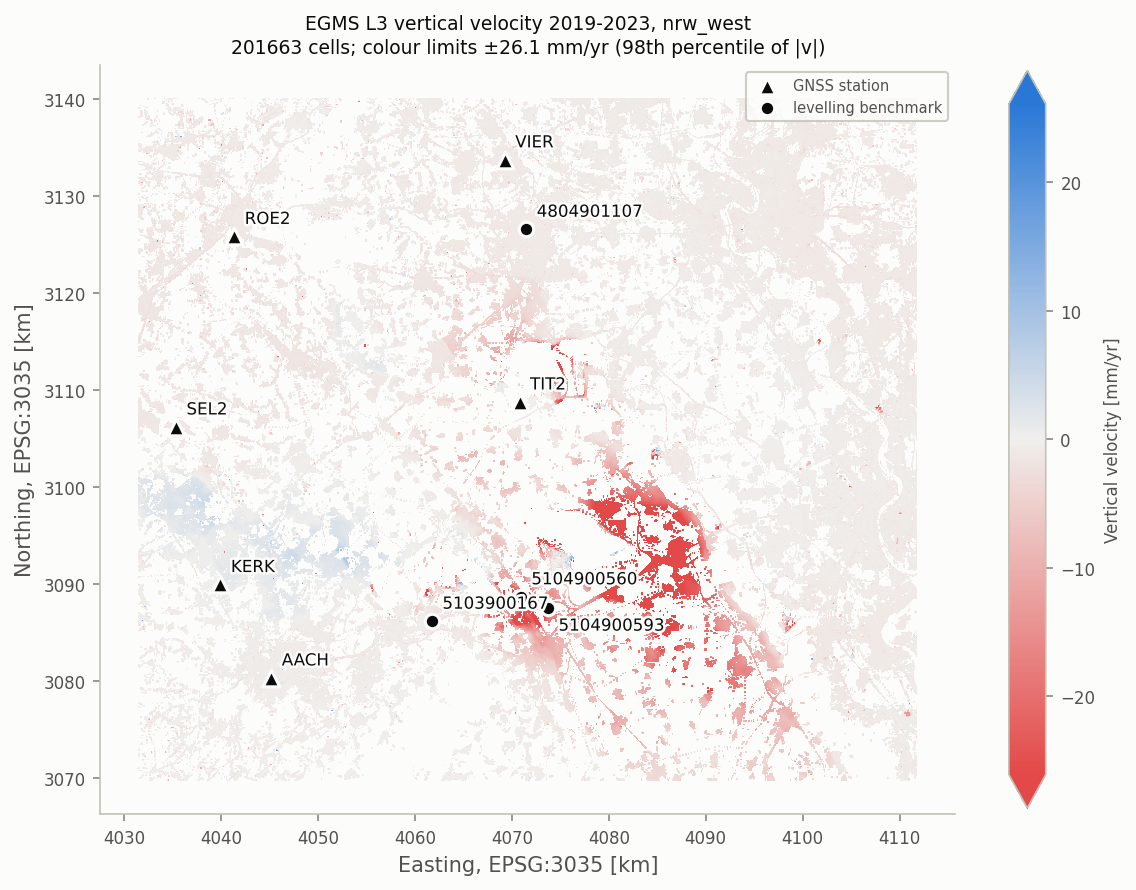

In [2]:
#@title Map of vertical speed from EGMS, 2019–2023
show(C['map'], 720)

**How to read the map:** the red areas are subsidence bowls next to open-pit lignite mines (up to tens of mm per
year). Blue means the ground goes up. Triangles are GNSS stations. Circles are the benchmarks shown over time below.

## 2. Does levelling confirm the motion from EGMS?

"Band (±2σ, median)",Width [mm],Benchmarks in the band: main variant,Benchmarks in the band: without the offset
EGMS noise (from rmse in the EGMS files),±2.0,12%,37%
usual EGMS–levelling difference (stable benchmarks),±4.4,32%,67%


**1216 benchmarks** with two levelling measurements and an EGMS cell. The usual EGMS–levelling difference is about **2.2 times** larger than the noise that EGMS declares.

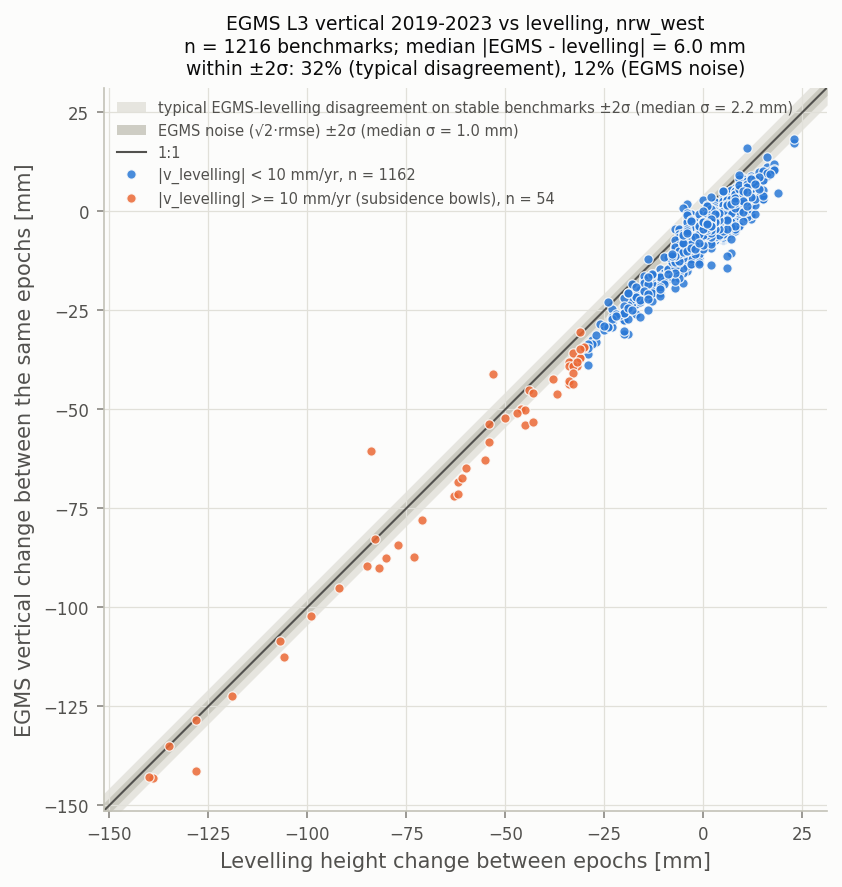

In [3]:
#@title Figure: height change from levelling and from EGMS (all benchmarks)
table(pd.DataFrame({
    'Band (±2σ, median)': ['EGMS noise (from rmse in the EGMS files)', 'usual EGMS–levelling difference (stable benchmarks)'],
    'Width [mm]': [f"±{k * noise['median_sigma_mm']:.1f}", f"±{k * emp['median_sigma_mm']:.1f}"],
    'Benchmarks in the band: main variant': [f"{noise['share_within_absolute']:.0%}", f"{emp['share_within_absolute']:.0%}"],
    'Benchmarks in the band: without the offset': [f"{noise['share_within_relative']:.0%}", f"{emp['share_within_relative']:.0%}"]}))
display(Markdown(f'**{len(ok)} benchmarks** with two levelling measurements and an EGMS cell. The usual EGMS–levelling '
                 f'difference is about **{emp["median_sigma_mm"] / noise["median_sigma_mm"]:.1f} times** larger '
                 f'than the noise that EGMS declares.'))
show(C['figure'], 640)

**How to read the figure:** each point is one benchmark. The horizontal axis shows the height change from
levelling, and the vertical axis the change from EGMS, both in mm between the same two days. The diagonal line means
perfect agreement. Orange points are benchmarks in subsidence bowls.

There are two bands around the line (±2σ):
- **the narrow, darker band is EGMS noise.** It comes from the `rmse` column in the EGMS files: the noise of one
  measurement around the EGMS model. A height change is the difference of two readings, so σ = √2 · rmse. This is the
  uncertainty that EGMS declares.
- **the wide, lighter band is the usual difference between EGMS and levelling.** We calculate it on benchmarks that do
  not move according to levelling: the spread of their speed differences, multiplied by the time between the
  measurements. It includes EGMS noise, levelling error, the difference between one point (the benchmark) and the
  average of a 100 × 100 m cell, and local EGMS errors.

**What this means:** only a small part of the benchmarks is inside the narrow band, but most are inside the wide band
(see the table above). So the EGMS `rmse` alone is too optimistic compared with a measurement on the ground: the real
difference is a few times larger than the noise the product declares (the ratio above the figure). We added the wide
band after we saw the narrow one. Both bands are for information only and have no pass/fail limit.

The points lie along the line from 0 to about −140 mm. The whole cloud is a little lower than the line: everywhere,
EGMS shows a little more subsidence than levelling. This is why more benchmarks are inside the bands after we remove this
common offset.

## 3. Three benchmarks over time

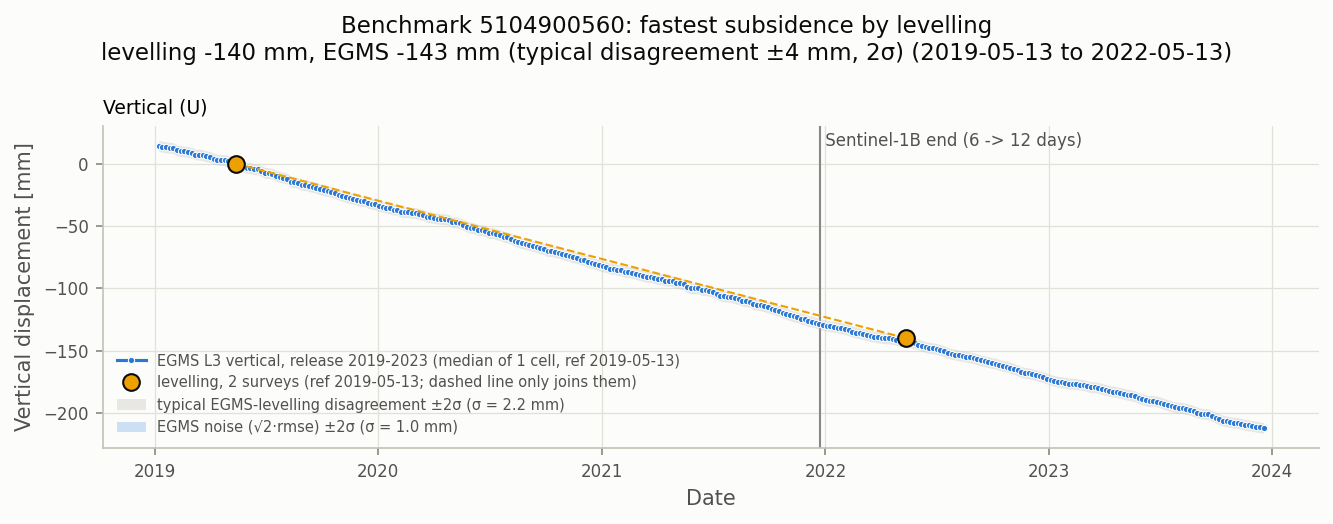

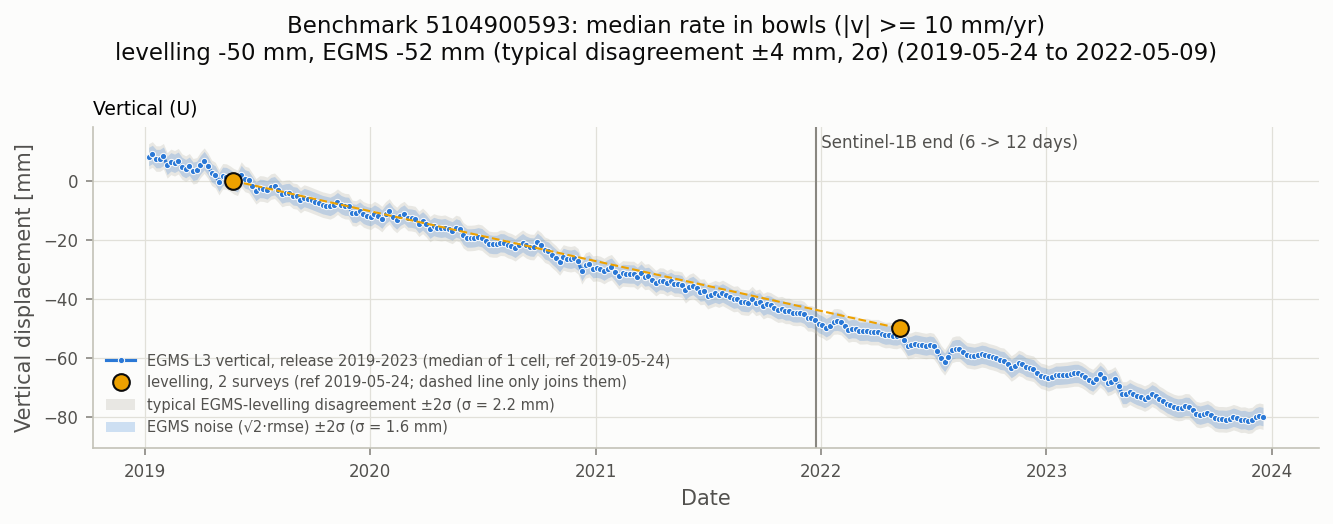

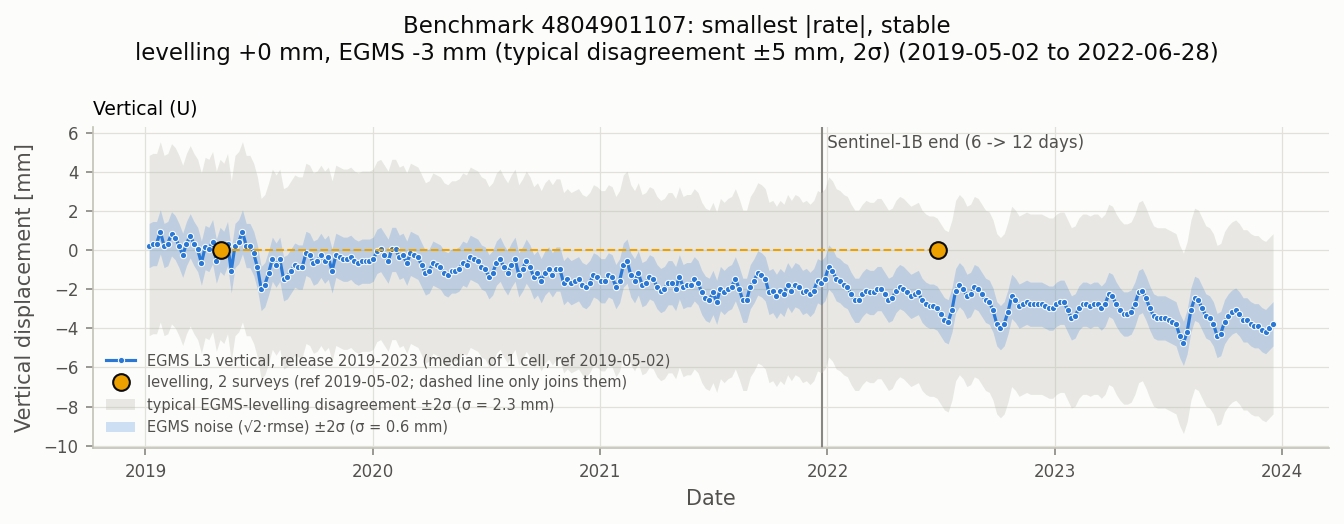

In [4]:
#@title Benchmarks chosen by a rule: fastest subsidence, median of the bowls, one stable benchmark
examples = dict((lab, bid) for bid, lab in _levelling_check_examples(res, CHECK_CONFIG['monitoring']['example_rule'], strong))
for lab in ('fastest subsidence by levelling', f'median rate in bowls (|v| >= {strong:g} mm/yr)', 'smallest |rate|, stable'):
    if lab not in examples:
        print(f'Rule "{lab}": the same benchmark as in an earlier figure, or no benchmarks in this group')
        continue
    show(C['figure'].parent / f"nrw_west_levelling_series_2019_2023_{examples[lab]}.png", 900)

**How to read the figures:** the blue line is EGMS, every 6–12 days. The blue band is EGMS noise (±2σ). The grey
band is the usual difference between EGMS and levelling (±2σ, from stable benchmarks). The big yellow dots are the two
levelling measurements; the dashed line only connects them, because there is no levelling between them. Both series
start at zero on the day of the first measurement. A yellow dot inside the grey band means that EGMS and levelling agree
as well as they usually do.

On the first two benchmarks, EGMS and levelling end at almost the same place. The third benchmark does not move, but
EGMS shows a few mm of subsidence there. The next section explains why.

## 4. A stable benchmark: is a difference of a few mm a problem?

Levelling says that the benchmark does not move, but EGMS shows a few mm of subsidence in 3 years. We split this into two
parts: a **common offset** (the same for all stable benchmarks, the dotted line) and **uncertainty** (the bands).

- Benchmark **4804901107**: levelling **+0.0 mm**, EGMS **-3.1 mm** in 3.16 years.
- All **307 stable benchmarks** have a common EGMS speed of **-1.22 mm/yr**; over this time it gives **-3.8 mm**. The median EGMS change in the group is -3.7 mm; 65% of the group have an EGMS change smaller than or equal to this benchmark.
- Without the common offset, the difference EGMS − levelling is **+0.8 mm**. It is inside the EGMS noise (±1.1 mm) and **is inside the usual difference** (±4.6 mm).

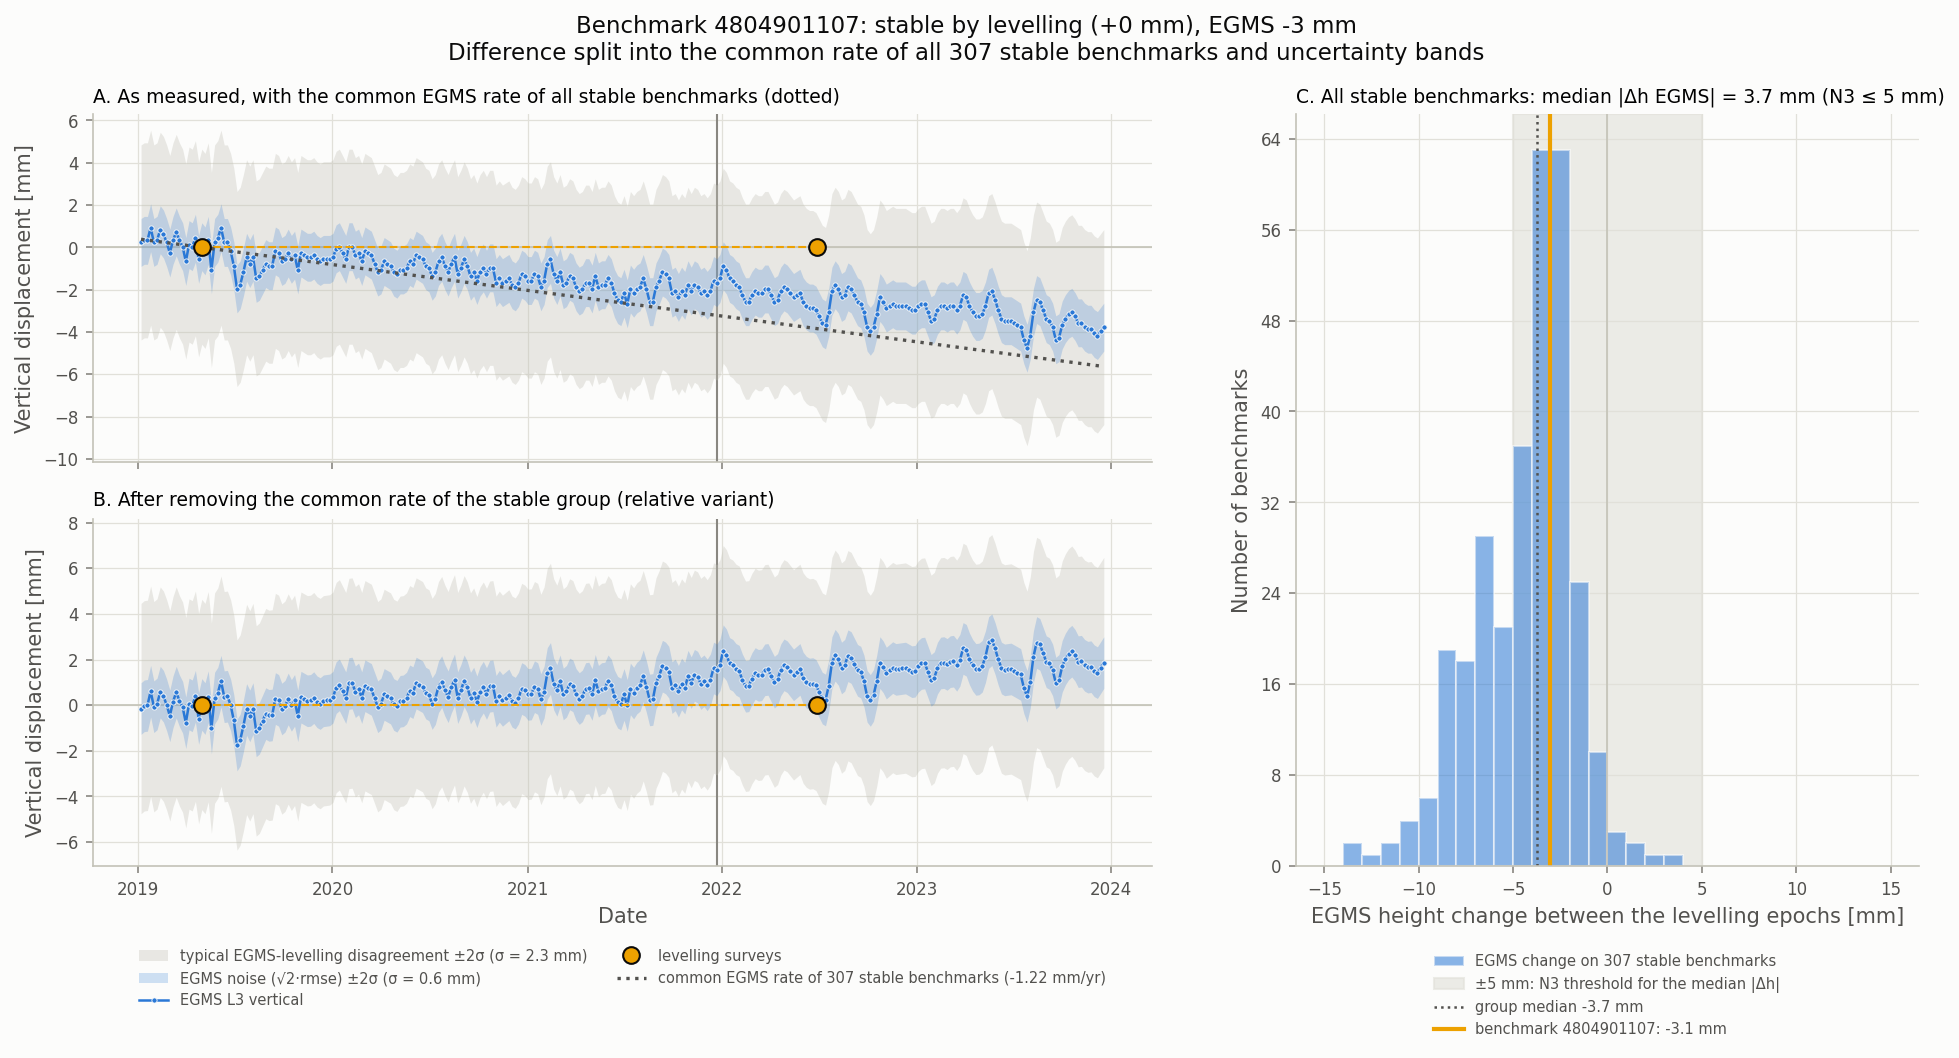

In [5]:
#@title The stable benchmark chosen by a rule: three panels and the numbers
bid = examples.get('smallest |rate|, stable')
if bid is None:
    raise ValueError('The rule did not find a stable benchmark (no benchmarks with |v| close to zero)')
r = ok[ok['benchmark_id'] == bid].iloc[0]
common = off['median_v_egms_group_mm_yr'] * r['dt_yr'] - off['median_v_lev_group_mm_yr'] * r['dt_yr']
after = r['diff_mm'] - common
group = ok.loc[ok['dh_lev_mm'].abs() <= stab_max, 'dh_egms_mm']
inside = lambda col: 'is inside' if abs(after) <= k * r[col] else 'is outside'
display(Markdown(
    f"- Benchmark **{bid}**: levelling **{r['dh_lev_mm']:+.1f} mm**, EGMS **{r['dh_egms_mm']:+.1f} mm** in {r['dt_yr']:.2f} years.\n"
    f"- All **{off['n_group']} stable benchmarks** have a common EGMS speed of **{off['offset_egms_minus_lev_mm_yr']:+.2f} mm/yr**; "
    f"over this time it gives **{common:+.1f} mm**. The median EGMS change in the group is {group.median():+.1f} mm; "
    f"{(group <= r['dh_egms_mm']).mean():.0%} of the group have an EGMS change smaller than or equal to this benchmark.\n"
    f"- Without the common offset, the difference EGMS − levelling is **{after:+.1f} mm**. It "
    f"{inside('sigma_dh_mm')} the EGMS noise (±{k * r['sigma_dh_mm']:.1f} mm) and "
    f"**{inside('sigma_emp_dh_mm')} the usual difference** (±{k * r['sigma_emp_dh_mm']:.1f} mm)."))
show(C['figure'].parent / f"nrw_west_levelling_stable_2019_2023_{bid}.png", 1000)

**How to read the figure:**
- **Panel A (as measured):** compare the blue EGMS line with the dotted line, the common speed of all stable benchmarks,
  **on the day of the second levelling measurement** (numbers above). There is no levelling before the first and after
  the second measurement, so those parts of the line do not show anything.
- **Panel B (without the common speed):** the same line after we remove the common offset. On the day of the second
  measurement, the difference EGMS − levelling is the value in the last point of the list above. The bands show if it
  is inside the uncertainty.
- **Panel C (all stable benchmarks):** how the EGMS changes are spread over all stable benchmarks, with this benchmark
  (orange line) and the median of the group. Criterion N3, set before the calculations, allows a median |Δh| of up to 5 mm.
- **Scale:** a few mm compared with −140 mm in the bowls is a few percent of the signal.

**An example from everyday life:** we measure how tall people are on a ferry. A tape measure that starts at the deck
shows that nobody changes. A GPS that starts at sea level shows that everybody goes down by 1 mm per year, because the
whole ferry slowly sinks. Both measurements are correct; they just have a different "zero". Levelling starts from the
reference benchmarks of its network, and EGMS from the ETRF2000 reference frame, through GNSS.

**What we know and what we only think:** we measured that the offset is the same for all stable benchmarks and that it is
within the limit. The different "zero" of the reference frames is the most likely reason for it, but we did not test this
(Even et al. 2024 do not give the reason either).

## 5. Results for the criteria set before the calculations

In [6]:
#@title Table of criteria N1–N4: main variant and relative variant
codes = ['N1', 'N2', 'N3', 'N4']
questions = {'N1': 'N1: usual difference EGMS − levelling', 'N2': 'N2: same direction of motion',
             'N3': 'N3: no false motion at stable benchmarks', 'N4': 'N4: offset in the EGMS speed'}
g, w = criteria(C['summary'], codes), criteria(C['summary_rel'], codes)
# N3 is not calculated in the relative variant: there, the stable benchmarks are the reference group.
w.loc[(w['code'] == 'N3') & (w['Passed'] == '— not calculated'), 'Result'] = 'does not apply (reference group)'
t = g[['code', 'Limit']].assign(Criterion=g['code'].map(questions), **{
    'Main variant': g['Result'] + ' ' + g['Passed'].str[:1],
    'Relative to stable benchmarks': g['code'].map(dict(zip(w['code'], w['Result'] + ' ' + w['Passed'].str[:1])))})
table(t[['Criterion', 'Limit', 'Main variant', 'Relative to stable benchmarks']])
display(Markdown(f"EGMS offset compared with levelling, on {off['n_group']} stable benchmarks: "
                 f"**{off['offset_egms_minus_lev_mm_yr']:+.2f} ± {off['offset_se_mm_yr']:.2f} mm/yr**"))

Criterion,Limit,Main variant,Relative to stable benchmarks
N1: usual difference EGMS − levelling,<= 5.0 mm,6.0 mm ✘,3.4 mm ✔
N2: same direction of motion,>= 90%,77% of benchmarks ✘,94% of benchmarks ✔
N3: no false motion at stable benchmarks,<= 5.0 mm,median |Δh_EGMS| 3.7 mm ✔,does not apply (reference group) —
N4: offset in the EGMS speed,|bias| <= 1.5 mm/yr,median -1.97 mm/yr ✘,median -1.00 mm/yr ✔


EGMS offset compared with levelling, on 307 stable benchmarks: **-1.22 ± 0.05 mm/yr**

**How to read the table:** ✔ = the criterion passes, ✘ = it fails, — = not calculated.
- The **main variant** compares the values directly, like Even et al. (2024). It fails N1, N2 and N4 because of a
  constant EGMS offset, not because of scatter.
- The **relative variant** (an extra check) first sets a common "zero" on benchmarks that do not move according to
  levelling. Then all calculated criteria pass. N3 is not calculated here, because these benchmarks are the reference.
- We added the relative variant after we saw the main result, so the main result does not change.

## 6. Subsidence bowls

In [7]:
#@title Benchmarks in the bowls (levelling speed of at least 10 mm/yr) and the others
gr, grw = pd.read_csv(C['groups']), pd.read_csv(C['groups_rel'])
for x in (gr, grw):     # row order from step_06.levelling_groups: all, bowls, other
    assert len(x) == 3 and str(x['grupa'].iat[0]).startswith(('all', 'wszys')), list(x['grupa'])
table(pd.DataFrame({'Group': ['all', f'bowls (≥ {strong:g} mm/yr)', 'others'],
                    'Benchmarks': gr['n'].astype(int),
                    'Usual difference [mm]': gr['median_abs_diff_mm'].round(1),
                    'Same direction': (gr['sign_agreement'] * 100).round(0).astype('Int64').astype(str) + '%',
                    'Slope (1 = same scale)': gr['slope'].round(2),
                    'Nearest GNSS station [km, median]': gr['dist_station_km_median'].round(1)}))
display(Markdown(f"Compared with the stable benchmarks, the usual difference in the bowls goes down from "
                 f"**{gr['median_abs_diff_mm'].iat[1]:.1f} mm** to **{grw['median_abs_diff_mm'].iat[1]:.1f} mm**."))

Group,Benchmarks,Usual difference [mm],Same direction,Slope (1 = same scale),"Nearest GNSS station [km, median]"
all,1216,6.0,77%,0.96,10.7
bowls (≥ 10 mm/yr),54,5.1,100%,0.98,8.5
others,1162,6.0,75%,0.89,10.8


Compared with the stable benchmarks, the usual difference in the bowls goes down from **5.1 mm** to **2.6 mm**.

**How to read the table:** in the bowls, EGMS and levelling agree on the direction of motion at every benchmark,
and the size of the motion is almost 1:1. The bowls are a few kilometres wide, but the GNSS model used to calibrate EGMS
has a grid of about 50 km. So the calibration could not "draw" the bowls: EGMS measured them by itself.

## 7. The largest differences

In [8]:
#@title The three largest differences in the bowls (we also show what does not fit)
bowls = ok[ok['v_lev_mm_yr'].abs() >= strong]
top = bowls.reindex(bowls['diff_mm'].abs().sort_values(ascending=False).index).head(3)
table(pd.DataFrame({'Benchmark': top['benchmark_id'], 'Levelling [mm]': top['dh_lev_mm'].round(1),
                    'EGMS [mm]': top['dh_egms_mm'].round(1), 'EGMS − levelling [mm]': top['diff_mm'].round(1),
                    f'EGMS noise ±{k:g}σ [mm]': (k * top['sigma_dh_mm']).round(1),
                    f'Usual difference ±{k:g}σ [mm]': (k * top['sigma_emp_dh_mm']).round(1),
                    'Meaning': top['diff_mm'].map(lambda d: 'EGMS: less subsidence' if d > 0 else 'EGMS: more subsidence')}))

Benchmark,Levelling [mm],EGMS [mm],EGMS − levelling [mm],EGMS noise ±2σ [mm],Usual difference ±2σ [mm],Meaning
5104900368,-84.0,-60.5,23.5,8.5,4.4,EGMS: less subsidence
5104900601,-73.0,-87.4,-14.4,1.7,4.4,EGMS: more subsidence
5104900095,-128.0,-141.2,-13.2,2.0,4.4,EGMS: more subsidence


**How to read the table:** in all three cases the direction of motion is the same. Part of the "more subsidence"
difference is the general EGMS offset (a few mm in 3 years). The benchmark with a large positive difference is a real
outlier. A likely reason (not tested) is that the benchmark is at the edge of a bowl, where the 100 × 100 m cell mixes
ground that sinks faster and slower.

## Key numbers

In [9]:
#@title Summary in numbers (read from the result files)
sm = pd.read_csv(C['summary'])
slope = en(sm.loc[sm['kryterium'].str.startswith(('Slope', 'Nachylenie')), 'wynik'].iat[0]).split(',')[0]
fastest = ok.sort_values('v_lev_mm_yr').iloc[0]
display(Markdown(
    f"- **{len(ok)} benchmarks** compared; the EGMS height change follows levelling almost 1:1 (slope {slope}).\n"
    f"- **Bowls ({int(gr['n'].iat[1])} benchmarks):** the same direction of motion at {gr['sign_agreement'].iat[1]:.0%} of them, "
    f"slope {gr['slope'].iat[1]:.2f}.\n"
    f"- **The fastest-subsiding benchmark {fastest['benchmark_id']}:** levelling {fastest['dh_lev_mm']:+.0f} mm, "
    f"EGMS {fastest['dh_egms_mm']:+.0f} mm.\n"
    f"- **EGMS offset:** {off['offset_egms_minus_lev_mm_yr']:+.2f} mm/yr compared with the stable benchmarks.\n"
    f"- **Uncertainty (±{k:g}σ, median):** EGMS noise ±{k * noise['median_sigma_mm']:.1f} mm, with "
    f"{noise['share_within_relative']:.0%} of benchmarks inside it after removing the offset; usual EGMS–levelling "
    f"difference ±{k * emp['median_sigma_mm']:.1f} mm, with {emp['share_within_relative']:.0%} inside it; the usual "
    f"difference is {emp['median_sigma_mm'] / noise['median_sigma_mm']:.1f} times larger than the noise."))

- **1216 benchmarks** compared; the EGMS height change follows levelling almost 1:1 (slope 0.96).
- **Bowls (54 benchmarks):** the same direction of motion at 100% of them, slope 0.98.
- **The fastest-subsiding benchmark 5104900560:** levelling -140 mm, EGMS -143 mm.
- **EGMS offset:** -1.22 mm/yr compared with the stable benchmarks.
- **Uncertainty (±2σ, median):** EGMS noise ±2.0 mm, with 37% of benchmarks inside it after removing the offset; usual EGMS–levelling difference ±4.4 mm, with 67% inside it; the usual difference is 2.2 times larger than the noise.

## Conclusion

- **Levelling, a measurement that does not use GNSS, confirms the subsidence that EGMS shows:** the bowls are in the
  same places, the direction of motion is the same and the size is almost the same.
- **EGMS measures the motion by itself** and does not only repeat the GNSS calibration: the bowls are much smaller
  than the grid of the calibration model.
- **Be careful with absolute values:** EGMS has an offset of about 1–2 mm per year. For motion below about 2 mm per year,
  and for absolute heights, you need a reference point measured on the ground.
- EGMS is an archive product, updated once a year. It does not detect sudden events.

**What is not here:** a comparison with GNSS in NRW (there is no subsiding station in the area, so the result is
unclear), "time to detection" curves (the method needs a fix) and our own Sentinel-1 processing (not run yet).
More details: `EGMS_Monitoring.ipynb` and `docs/evidence/F10_NRW_niwelacja_EGMS.md`.

**Sources:** EGMS (Copernicus Land Monitoring Service); levelling: Geobasis NRW; comparison with levelling in NRW:
Even, Westerhaus, Kutterer (2024), PFG 92:253–270; limits: Koudogbo et al. (2025) EGMS Validation Report.

---

The full notebook and all the code are on GitHub: [Showcase_2_Levelling_NRW.ipynb](https://github.com/geoworldlook/egms-check/blob/main/notebooks/Showcase_2_Levelling_NRW.ipynb) in the [egms-check](https://github.com/geoworldlook/egms-check) repository.